# K-Means Clustering on NBA Point Guards

**Objective:** Group NBA point guards using performance indicators and compare manual clustering with scikit-learn.

**Dataset used:** `data/nba_2013.csv`

**Main techniques used:** Feature engineering, Euclidean distance, manual K-Means steps, centroid updates, scikit-learn KMeans


In [1]:
import pandas as pd
nba = pd.read_csv('data/nba_2013.csv')
nba.head(3)


## Filter Point Guards

The analysis focuses on point guards so player roles remain comparable across the dataset.


In [2]:
point_guards = nba[nba['pos'] == 'PG']
point_guards


In [3]:
pd.options.mode.chained_assignment = None
point_guards['ppg'] = point_guards['pts'] / point_guards['g']


In [4]:
#verifier que ppg a été ajouté
point_guards[['pts' ,'g','ppg']].head(3)


,pts,g,ppg
24,930,71,13.098592
29,150,20,7.500000
30,660,79,8.354430


## Create the Assist-to-Turnover Ratio

This step builds the `ATR` feature and removes players with zero turnovers to avoid division by zero.


In [5]:
point_guards = point_guards[point_guards['tov'] != 0]
point_guards['atr'] = point_guards['ast'] / point_guards['tov']


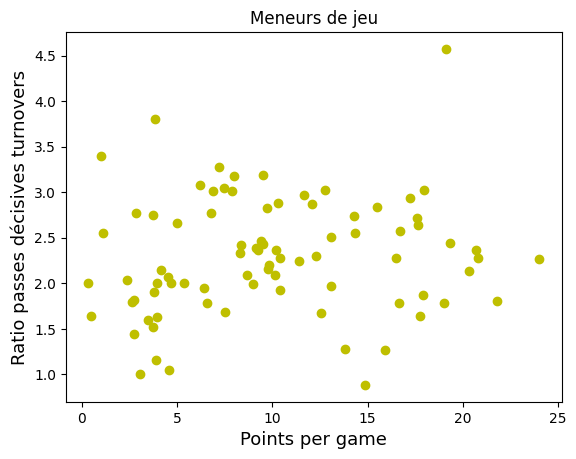

In [6]:
import matplotlib.pyplot as plt
plt.scatter(point_guards['ppg'], point_guards['atr'] , c ='y')
plt.xlabel("Points per game" ,fontsize=13) 
plt.ylabel("Ratio passes décisives turnovers", fontsize=13)
plt.title("Meneurs de jeu")
plt.show()


## Initialize K-Means Manually

The notebook first recreates the K-Means process manually to understand how centroid assignment works.


In [7]:
import numpy as np
num_clusters = 5
#fonction random pour choisir les points initiaux
random_initial_points = np.random.choice(point_guards.index, size=num_clusters)
#afficher les points initiaux
centroids = point_guards.loc[random_initial_points] 


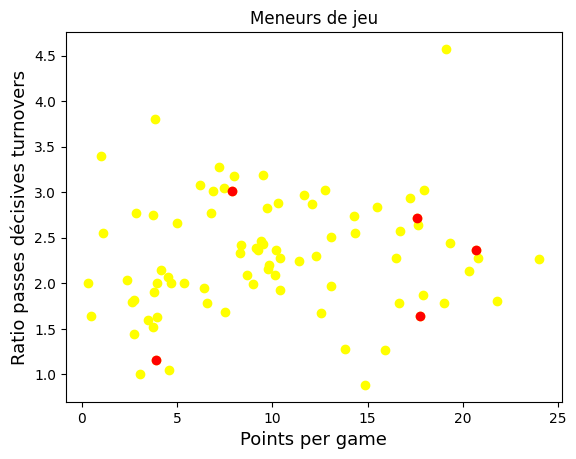

In [8]:
#visualiser les centroides
plt.scatter(point_guards['ppg'] ,point_guards['atr'],c='yellow')
plt.scatter(centroids['ppg'] ,centroids['atr'],c='red')
plt.xlabel("Points per game" ,fontsize=13)
plt.ylabel("Ratio passes décisives turnovers", fontsize=13)
plt.title("Meneurs de jeu")
plt.show()


## Store the Centroids

Centroids are stored in a dictionary so each cluster can be updated during the iterative process.


In [9]:
def centroids_to_dict(centroids):
    dictionary = dict()
    #compteur itératif utilisé pour générer un cluster_id
    counter = 0 
    for index, row in centroids.iterrows():
        coordinates = [row['ppg'], row['atr']]
        dictionary[counter] = coordinates
        counter += 1
    return dictionary
centroids_dict = centroids_to_dict(centroids)
centroids_dict


{0: [20.670731707317074, 2.3678756476683938],
 1: [17.580645161290324, 2.715],
 2: [17.74418604651163, 1.6433566433566433],
 3: [3.869565217391304, 1.1612903225806452],
 4: [7.875, 3.016949152542373]}

In [10]:
import math
def calculate_distance(centroids , plyer_value):
    root_distance = 0
    for x in range(0,len(centroids)):
        difference = centroids[x] - plyer_value[x]
        squared_difference = difference ** 2 
        root_distance += squared_difference
    euclid_distance = math.sqrt(root_distance)
    return euclid_distance
#testerpour q et p
q = [5,2]
p=  [3,1]
print(calculate_distance(q,p))


2.23606797749979


## Assign Players to Clusters

Each point guard is assigned to the closest centroid using Euclidean distance.


In [11]:
def  assign_to_cluster(row):
    lowest_distance =-1
    closest_cluster = -1
    for cluster_id, centroid in centroids_dict.items():
        df_row = [row['ppg'], row['atr']]
        euclidean_distance = calculate_distance(centroid, df_row)
        
        if lowest_distance == -1:
            lowest_distance = euclidean_distance
            closest_cluster = cluster_id
        elif euclidean_distance < lowest_distance:
            lowest_distance = euclidean_distance
            closest_cluster = cluster_id
    return closest_cluster

point_guards['cluster' ] = point_guards.apply(lambda row: assign_to_cluster(row), axis=1)


In [12]:
point_guards 


## Visualize the Clusters


In [13]:
def visualize_cluster(df ,num_clusters):
    colors = ['b','g','r','c','m','y','k']
    for n in range(num_clusters):
        clustered_df = df[df['cluster'] == n]
        plt.scatter(clustered_df['ppg'], clustered_df['atr'], c=colors[n-1])
        plt.xlabel("Points per game" ,fontsize=13)
        plt.ylabel("Assists per game" ,fontsize=13)
        plt.title("Clustering of Point Guards" ,fontsize=15)
    plt.show()
        
        


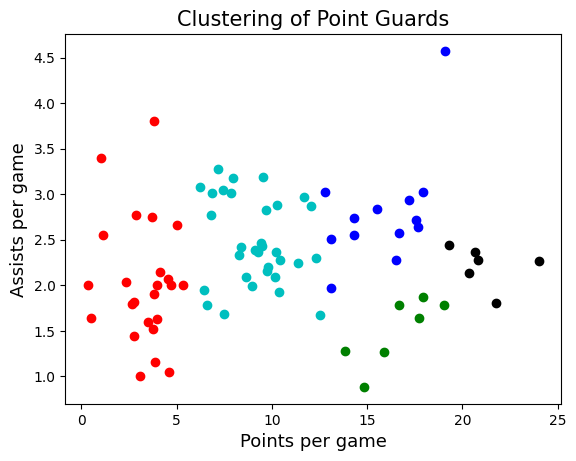

In [14]:
visualize_cluster(point_guards, 5)


## Recalculate the Centroids

After assigning players to clusters, the centroid positions are updated from the current group averages.


In [15]:
def recalculate_centroids(df):
    new_centroids_dict  = dict()
    for cluster_id in range(0,num_clusters):
        values_in_cluster = df[df['cluster'] == cluster_id]
        #calculer les nouvelles coordonnées du centroide en prenant la moyenne des points dans le cluster
        new_centroid = [np.average(values_in_cluster['ppg']), np.average(values_in_cluster['atr'])]
        new_centroids_dict[cluster_id] = new_centroid
    return new_centroids_dict
centroids_dict = recalculate_centroids(point_guards)
centroids_dict


{0: [np.float64(21.15586043254053), np.float64(2.2149853702025464)],
 1: [np.float64(15.829290838109273), np.float64(2.797056765275668)],
 2: [np.float64(16.563651488199746), np.float64(1.5018113397448072)],
 3: [np.float64(3.2510322129176843), np.float64(2.032060176491893)],
 4: [np.float64(9.141860142576867), np.float64(2.4774993925345212)]}

## Repeat the Assignment Step


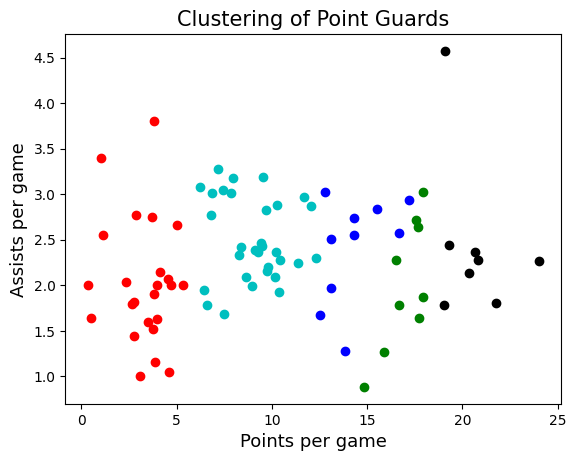

In [16]:
point_guards['cluster'] = point_guards.apply(lambda row: assign_to_cluster(row), axis=1)
visualize_cluster(point_guards, num_clusters)


## Iterate Until the Clusters Stabilize


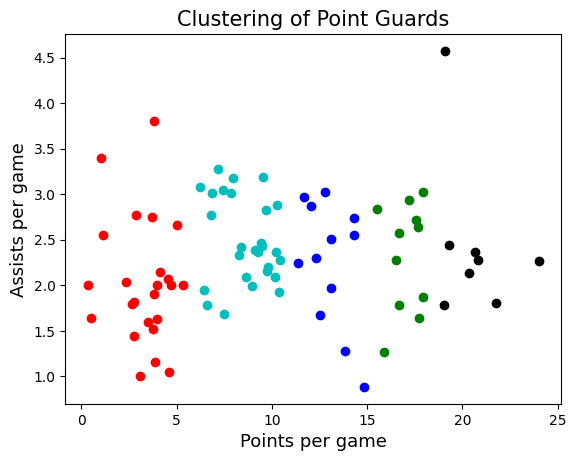

In [18]:
centroids_dict = recalculate_centroids(point_guards) 
point_guards['cluster'] = point_guards.apply(lambda row : assign_to_cluster(row) ,axis= 1)  
visualize_cluster(point_guards , num_clusters )


## Compare with Scikit-Learn

The final section repeats the clustering task with `sklearn.cluster.KMeans`.


In [19]:
nba = pd.read_csv('data/nba_2013.csv')
point_guards = nba[nba['pos'] == 'PG']
point_guards['ppg'] = point_guards['pts'] / point_guards['g']
point_guards = point_guards[point_guards['tov'] != 0]
point_guards['atr'] = point_guards['ast'] / point_guards['tov']


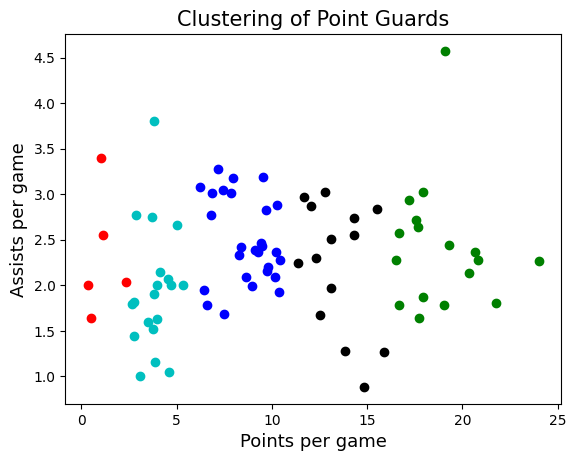

In [20]:
from sklearn.cluster import KMeans
Kmeans = KMeans(n_clusters=num_clusters)
Kmeans.fit(point_guards[['ppg','atr']])
point_guards['cluster'] = Kmeans.labels_
visualize_cluster(point_guards, num_clusters)


## Conclusion

**What was done:** Engineered player performance features, recreated K-Means manually, and compared the result with scikit-learn.

**What was learned:** K-Means becomes easier to understand when centroid assignment and update steps are implemented directly.

**Possible improvements:** Standardize features, test additional player groups, and evaluate cluster stability.
